# Computational Project: From Potential Energy to Oscillation

## Investigation of a damped mass-spring oscillator

**Classical Mechanics - Taylor, Chapters 4 and 5**

This project connects the energy description of motion to the equation of motion of an oscillator. You will:

1. write the potential energy and use $F=-dU/dx$;
2. construct the equation of motion for a mass-spring oscillator with damping;
3. enter the physics into one input cell;
4. visualize displacement, phase space, energy transfer, force, and dissipated power;
5. compare damped motion with simple harmonic motion.

You are **not expected to know Python**. Edit only the green **STUDENT INPUT** cell. Run every other cell without changing it.

### Physical system

A mass $m$ moves horizontally and is attached to a spring with force constant $k$. The coordinate $x$ measures displacement from equilibrium. A damping force may act opposite the velocity:

$$F_{\rm damping}=-c\dot{x}.$$

The default model is underdamped, so the mass oscillates while its amplitude and mechanical energy gradually decrease.

## Part A - Do the physics first

Before running the simulation, include the following in your submitted work.

1. Sketch the potential-energy function $U(x)$ and identify the stable equilibrium point.
2. Starting from the spring potential energy, calculate the conservative force using $F=-dU/dx$.
3. Add the damping force and write Newton's second law as a differential equation for $x(t)$.
4. Predict the shape of the displacement-versus-time.
5. Predict whether the total mechanical energy $E=K+U$ will be constant when $c>0$. Explain using the work-energy theorem.

### Expressions accepted by the notebook

| Entry | Meaning | Default model |
|---|---|---|
| `U` | Potential energy | `0.5*k*x**2` |
| `F_conservative` | Force obtained from $-dU/dx$ | `-k*x` |
| `F_nonconservative` | Damping or other nonconservative force | `-c*v` |

Use `*` for multiplication and `**` for powers. For example, $x^2$ is entered as `x**2`. The allowed symbols are `t`, `x`, `v`, `m`, `k`, and `c`.

In [1]:
#@title STUDENT INPUT - Edit only this cell { display-mode: "form" }
# Enter the physics expressions that you derived.
U = "0.5*k*x**2" #@param {type:"string"}
F_conservative = "-k*x" #@param {type:"string"}
F_nonconservative = "-c*v" #@param {type:"string"}

# Physical parameters in SI units
m = 1.0 #@param {type:"number"}
k = 4.0 #@param {type:"number"}
c = 0.4 #@param {type:"number"}

# Initial conditions
initial_displacement = 0.50 #@param {type:"number"}
initial_velocity = 0.0 #@param {type:"number"}

# Simulation duration
maximum_time = 16.0 #@param {type:"number"}

print("Inputs saved. Now run the next cell.")

Inputs saved. Now run the next cell.


## Part B - Run the model

The next cell checks your expressions, constructs the equation of motion, and solves it numerically. It also compares your conservative force with the slope of your potential-energy function. **Do not edit it.**

In [2]:
#@title SIMULATION ENGINE - Run, but do not edit { display-mode: "form" }
import ast
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

if m <= 0 or k <= 0 or c < 0 or maximum_time <= 0:
    raise ValueError("Use m > 0, k > 0, c >= 0, and maximum_time > 0.")

allowed_names = {"t", "x", "v", "m", "k", "c"}

def make_expression(expression, name):
    try:
        tree = ast.parse(expression, mode="eval")
    except Exception as exc:
        raise ValueError(f"Could not read {name} = {expression!r}. Check * signs and parentheses.") from exc
    unknown = {node.id for node in ast.walk(tree) if isinstance(node, ast.Name)} - allowed_names
    if unknown:
        raise ValueError(f"Unknown symbol(s) in {name}: {unknown}. Use only the symbols in the table.")
    permitted = (ast.Expression, ast.BinOp, ast.UnaryOp, ast.Name, ast.Load,
                 ast.Constant, ast.Add, ast.Sub, ast.Mult, ast.Div, ast.Pow,
                 ast.USub, ast.UAdd)
    if any(not isinstance(node, permitted) for node in ast.walk(tree)):
        raise ValueError(f"{name} contains an unsupported operation.")
    compiled = compile(tree, f"<{name}>", "eval")
    def evaluate(t, x, v, m, k, c):
        values = {"t": t, "x": x, "v": v, "m": m, "k": k, "c": c}
        return eval(compiled, {"__builtins__": {}}, values)
    return evaluate

potential = make_expression(U, "U")
force_c = make_expression(F_conservative, "F_conservative")
force_nc = make_expression(F_nonconservative, "F_nonconservative")

def derivatives(t, state):
    x, v = state
    fc = float(force_c(t, x, v, m, k, c))
    fnc = float(force_nc(t, x, v, m, k, c))
    return [v, (fc + fnc)/m]

solution = solve_ivp(derivatives, (0, maximum_time),
                     [initial_displacement, initial_velocity],
                     dense_output=True, rtol=1e-9, atol=1e-11,
                     max_step=maximum_time/1200)

time = np.linspace(0, maximum_time, 1200)
x, v = solution.sol(time)
U_values = np.array([potential(T, X, V, m, k, c) for T, X, V in zip(time, x, v)], dtype=float)
if U_values.ndim == 0: U_values = np.full_like(time, U_values)
Fc = np.array([force_c(T, X, V, m, k, c) for T, X, V in zip(time, x, v)], dtype=float)
Fnc = np.array([force_nc(T, X, V, m, k, c) for T, X, V in zip(time, x, v)], dtype=float)
if Fc.ndim == 0: Fc = np.full_like(time, Fc)
if Fnc.ndim == 0: Fnc = np.full_like(time, Fnc)
Fnet = Fc + Fnc
K_values = 0.5*m*v**2
E_values = K_values + U_values
power_nc = Fnc*v

# Check F_conservative against -dU/dx using a numerical derivative.
x_scale = max(np.max(np.abs(x)), 1.0)
h = 1e-5*x_scale
force_from_U = np.array([-(potential(T, X+h, V, m, k, c)-potential(T, X-h, V, m, k, c))/(2*h)
                         for T, X, V in zip(time, x, v)], dtype=float)
force_mismatch = np.max(np.abs(Fc-force_from_U))/max(1.0, np.max(np.abs(force_from_U)))

omega0 = np.sqrt(k/m)
critical_c = 2*np.sqrt(m*k)
if c < critical_c:
    regime = "underdamped" if c > 0 else "undamped"
elif np.isclose(c, critical_c):
    regime = "critically damped"
else:
    regime = "overdamped"

peak_indices, _ = find_peaks(x)
measured_period = np.mean(np.diff(time[peak_indices])) if len(peak_indices) >= 2 else np.nan

print(f"Model: U = {U}; F_cons = {F_conservative}; F_nc = {F_nonconservative}")
print(f"Damping regime: {regime}")
print(f"Natural angular frequency sqrt(k/m): {omega0:.4f} rad/s")
print(f"Undamped period: {2*np.pi/omega0:.4f} s")
if np.isfinite(measured_period):
    print(f"Measured period from positive peaks: {measured_period:.4f} s")
print(f"Initial mechanical energy: {E_values[0]:.5f} J")
print(f"Final mechanical energy:   {E_values[-1]:.5f} J")
if force_mismatch < 1e-4:
    print("Physics check passed: F_conservative agrees with -dU/dx.")
else:
    print("WARNING: F_conservative does not agree with -dU/dx. Recheck Part A.")

Model: U = 0.5*k*x**2; F_cons = -k*x; F_nc = -c*v
Damping regime: underdamped
Natural angular frequency sqrt(k/m): 2.0000 rad/s
Undamped period: 3.1416 s
Measured period from positive peaks: 3.1560 s
Initial mechanical energy: 0.50000 J
Final mechanical energy:   0.00090 J
Physics check passed: F_conservative agrees with -dU/dx.


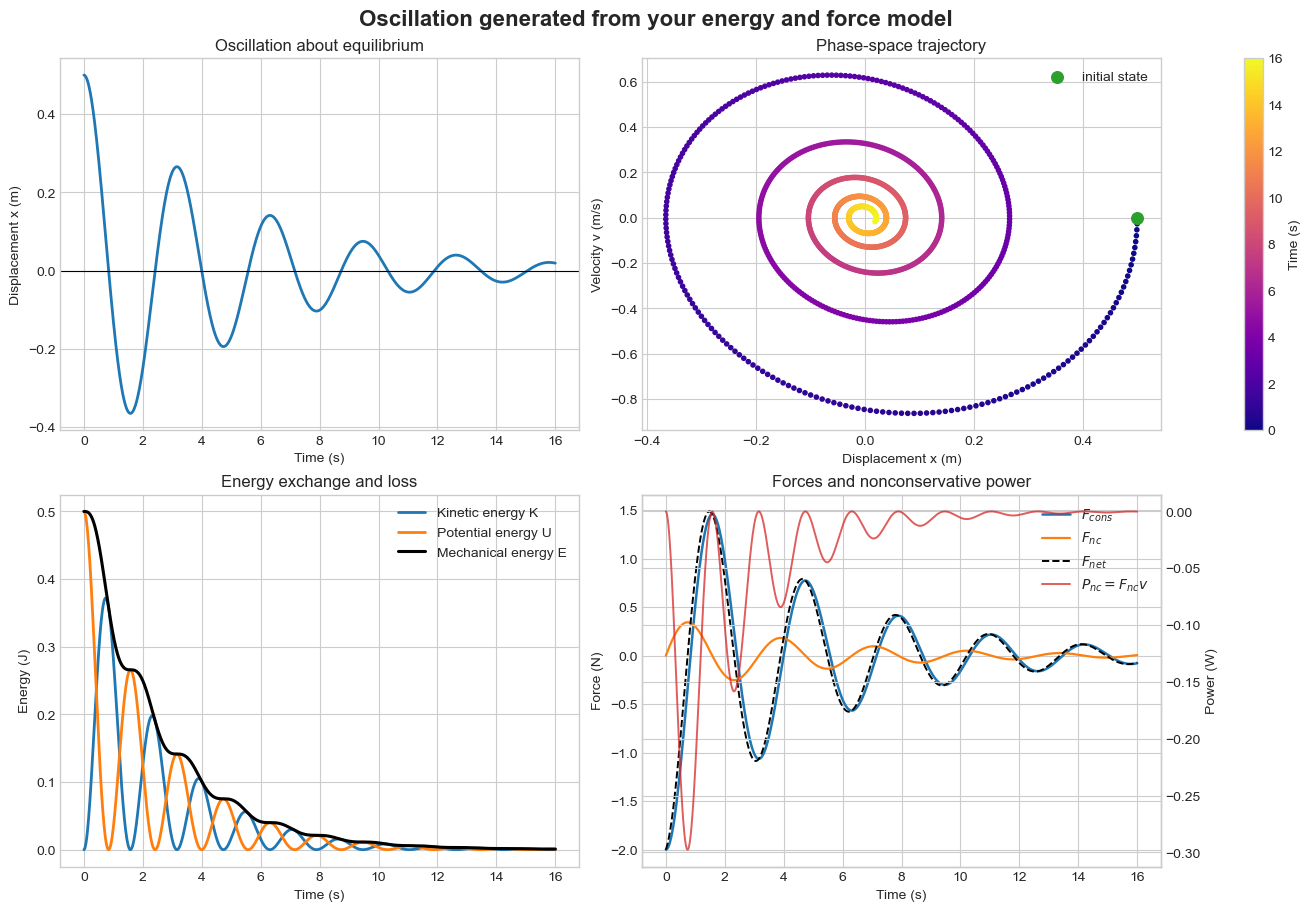

In [3]:
#@title DESCRIPTIVE PLOTS - Run, but do not edit { display-mode: "form" }
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

# Displacement
axes[0,0].plot(time, x, color="tab:blue", lw=2)
axes[0,0].axhline(0, color="black", lw=0.8)
axes[0,0].set(xlabel="Time (s)", ylabel="Displacement x (m)", title="Oscillation about equilibrium")

# Phase space
phase = axes[0,1].scatter(x, v, c=time, cmap="plasma", s=9)
axes[0,1].scatter([x[0]], [v[0]], color="tab:green", s=70, label="initial state")
axes[0,1].set(xlabel="Displacement x (m)", ylabel="Velocity v (m/s)", title="Phase-space trajectory")
axes[0,1].legend(loc="best")
fig.colorbar(phase, ax=axes[0,1], label="Time (s)")

# Energies
axes[1,0].plot(time, K_values, label="Kinetic energy K", lw=2)
axes[1,0].plot(time, U_values, label="Potential energy U", lw=2)
axes[1,0].plot(time, E_values, label="Mechanical energy E", color="black", lw=2.2)
axes[1,0].set(xlabel="Time (s)", ylabel="Energy (J)", title="Energy exchange and loss")
axes[1,0].legend(loc="best")

# Forces and nonconservative power
axF = axes[1,1]
axP = axF.twinx()
lines = []
lines += axF.plot(time, Fc, label="$F_{cons}$", lw=1.8)
lines += axF.plot(time, Fnc, label="$F_{nc}$", lw=1.6)
lines += axF.plot(time, Fnet, label="$F_{net}$", color="black", lw=1.4, ls="--")
lines += axP.plot(time, power_nc, label="$P_{nc}=F_{nc}v$", color="tab:red", lw=1.4, alpha=.75)
axF.set(xlabel="Time (s)", ylabel="Force (N)", title="Forces and nonconservative power")
axP.set_ylabel("Power (W)")
axF.legend(lines, [line.get_label() for line in lines], loc="best")

fig.suptitle("Oscillation generated from your energy and force model", fontsize=16, fontweight="bold")
plt.show()

## Part C - Interpret the model

Answer in complete sentences and cite specific numerical values or plot features.

1. Report the damping regime, undamped period, measured period, initial energy, and final energy.
2. Explain how the slope of $U(x)$ determines the direction of the conservative force on either side of equilibrium.
3. Identify when kinetic energy is greatest and when potential energy is greatest. Relate these times to the displacement and speed.
4. Explain the shape of the phase-space trajectory. Why does it spiral inward when $c>0$?
5. Compare the total mechanical-energy curve with the nonconservative power. How does the sign of $P_{\rm nc}=F_{\rm nc}v$ explain the energy change?

## Part D - Controlled comparison

Return to the **STUDENT INPUT** cell and set `c = 0`. Keep every other entry unchanged, then rerun the notebook from that cell downward.

6. What happens to total mechanical energy when damping is removed?
7. How do the displacement and phase-space plots change? Compare the measured period with $2\pi\sqrt{m/k}$.
8. Explain why kinetic and potential energy continue to change even though total mechanical energy is constant.

## Optional extension

Choose one physically meaningful change: double the mass, double the spring constant, begin with a nonzero initial velocity, or investigate an instructor-approved potential-energy function. Predict the effect on the period and energy before rerunning the notebook.

> **Submission:** Include your derivation, predictions, answers to Parts C and D, and plots from both damped and undamped trials. Your physics model and interpretation are the focus, not the code.